# Predictive Maintenance: Forecasting Component Failures from Machine Data

**Question:** Will a machine have a component failure within the next 24 hours, and if so, which component?

Using hourly sensor data, warning messages, maintenance records and machine metadata for 100 machines over one year,
this notebook builds a model that a service team could use to plan visits and bring the right spare part *before* a failure happens.

**Steps**
1. Load and understand the data
2. Which components and machines fail most often?
3. Do failures announce themselves in the data?
4. Feature engineering (sensors, warnings, maintenance history, machine metadata)
5. Target: failure of which component within the next 24 hours
6. Time-based train/test split
7. Train a gradient boosting model
8. Evaluate per component
9. Which features matter most?

*Dataset:* Microsoft Azure Predictive Maintenance dataset (simulated data).

## Setup

In [1]:
!git clone -q --depth 1 https://github.com/ashishpatel26/Predictive_Maintenance_using_Machine-Learning_Microsoft_Casestudy.git pdm_repo
DATA_DIR = 'pdm_repo/data/'

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

RANDOM_STATE = 123
COMPONENTS = ['comp1', 'comp2', 'comp3', 'comp4']
SENSORS = ['volt', 'rotate', 'pressure', 'vibration']
ERRORS = ['error1', 'error2', 'error3', 'error4', 'error5']

## 1. Load the data

| Table | One row means |
|---|---|
| telemetry | hourly mean of voltage, rotation, pressure and vibration for one machine |
| errors | a warning message (the machine keeps running) |
| maint | a component was replaced (scheduled or after a failure) |
| failures | a component failed and was replaced |
| machines | model and age of a machine |

In [3]:
telemetry = pd.read_csv(DATA_DIR + 'PdM_telemetry.csv', parse_dates=['datetime'])
errors    = pd.read_csv(DATA_DIR + 'PdM_errors.csv',    parse_dates=['datetime'])
maint     = pd.read_csv(DATA_DIR + 'PdM_maint.csv',     parse_dates=['datetime'])
failures  = pd.read_csv(DATA_DIR + 'PdM_failures.csv',  parse_dates=['datetime'])
machines  = pd.read_csv(DATA_DIR + 'PdM_machines.csv')

for name, df in [('telemetry', telemetry), ('errors', errors), ('maint', maint),
                 ('failures', failures), ('machines', machines)]:
    print(f'{name:10s} {df.shape}')

telemetry  (876100, 6)
errors     (3919, 3)
maint      (3286, 3)
failures   (761, 3)
machines   (100, 3)


## 2. Which components and machines fail most often?

In [4]:
failures_m = failures.merge(machines, on='machineID')
failures_m['failure'].value_counts().sort_index()

failure
comp1    192
comp2    259
comp3    131
comp4    179
Name: count, dtype: int64

Raw counts per model would be misleading because the models have different fleet sizes (e.g. 35 machines of model3, 16 of model1).
The table below therefore shows **failures per machine and year**.

In [5]:
counts = failures_m.groupby(['model', 'failure']).size().unstack(fill_value=0)
per_machine = counts.div(machines['model'].value_counts(), axis=0).round(2)
per_machine.assign(total=per_machine.sum(axis=1).round(1))

failure,comp1,comp2,comp3,comp4,total
model,,,,,
model1,2.06,2.88,4.25,2.62,11.8
model2,1.76,2.41,3.71,2.00,9.9
model3,1.94,2.54,0.00,1.83,6.3
model4,1.91,2.59,0.00,1.22,5.7


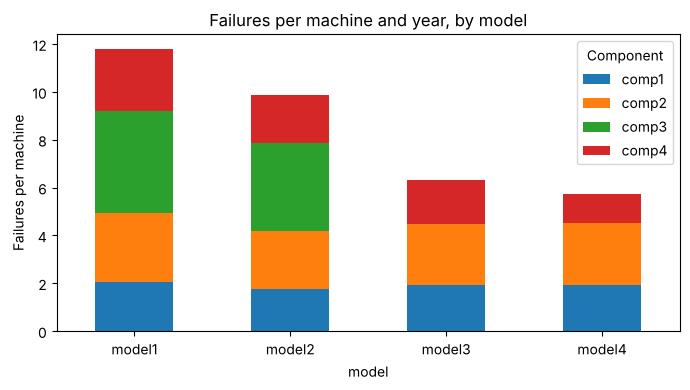

In [6]:
per_machine.plot(kind='bar', stacked=True, rot=0, figsize=(7, 4))
plt.title('Failures per machine and year, by model')
plt.ylabel('Failures per machine')
plt.legend(title='Component')
plt.tight_layout()
plt.savefig('failures_per_model.png', dpi=150, bbox_inches='tight')
plt.show()

- **comp2** fails most often overall.
- **comp3 only fails in model1 and model2**, where it is the most frequent failure. In model3 and model4 it is maintained but never fails.
- **model1** has about twice as many failures per machine as model4.

Is this just because some models are older? Model1 and model3 have almost the same average age, yet model1 fails far more often,
so the difference is driven by comp3 rather than by age. Older machines do fail more often overall:

In [7]:
machine_stats = machines.copy()
machine_stats['n_failures'] = machine_stats['machineID'].map(failures.groupby('machineID').size()).fillna(0)

print(machine_stats.groupby('model')['age'].mean().round(1), '\n')
age_groups = pd.cut(machine_stats['age'], bins=[-1, 5, 10, 15, 20])
machine_stats.groupby(age_groups, observed=True)['n_failures'].mean().round(1)

model
model1    12.2
model2    12.8
model3    12.0
model4     9.3
Name: age, dtype: float64 



age
(-1, 5]     5.9
(5, 10]     5.4
(10, 15]    9.2
(15, 20]    9.5
Name: n_failures, dtype: float64

## 3. Do failures announce themselves?

Example: vibration of machine 1 over the year, with its comp4 failures marked in red.

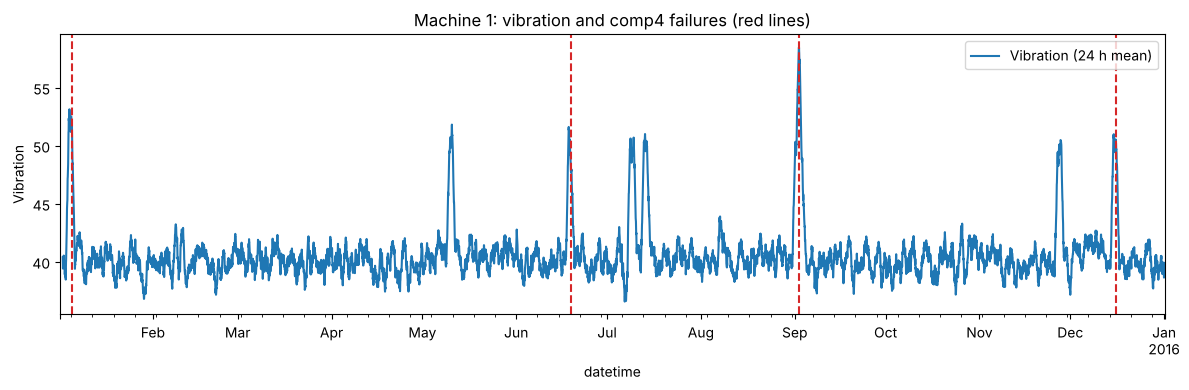

In [8]:
machine_id = 1
tel = telemetry[telemetry['machineID'] == machine_id].set_index('datetime')
fail = failures[(failures['machineID'] == machine_id) & (failures['failure'] == 'comp4')]

tel['vibration'].rolling(24).mean().plot(figsize=(12, 4), label='Vibration (24 h mean)')
for t in fail['datetime']:
    plt.axvline(t, color='tab:red', linestyle='--')
plt.title(f'Machine {machine_id}: vibration and comp4 failures (red lines)')
plt.ylabel('Vibration')
plt.legend()
plt.tight_layout()
plt.savefig('vibration_example.png', dpi=150, bbox_inches='tight')
plt.show()

Vibration rises about one to two days before each comp4 failure.
But there are also peaks **without** a failure (May, July, November). Vibration alone would cause false alarms,
which is why the model below combines several signals.

## 4. Feature engineering

Each row describes **one machine at one hour** using only information available at that moment.

### 4.1 Sensors: level and variability over the last 24 hours

In [9]:
telemetry = telemetry.sort_values(['machineID', 'datetime'])
rolled = telemetry.groupby('machineID')[SENSORS].rolling(24)

features = telemetry[['datetime', 'machineID']].copy()
features[[s + '_mean_24h' for s in SENSORS]] = rolled.mean().values
features[[s + '_std_24h' for s in SENSORS]] = rolled.std().values
features = features.dropna()
features.shape

(873800, 10)

### 4.2 Warnings: number of each error type in the last 24 hours

In [10]:
err = pd.get_dummies(errors, columns=['errorID'], prefix='', prefix_sep='', dtype=int)
err = err.groupby(['machineID', 'datetime']).sum().reset_index()

grid = telemetry[['datetime', 'machineID']].merge(err, on=['datetime', 'machineID'], how='left').fillna(0)
grid = grid.sort_values(['machineID', 'datetime'])
error_counts = grid.groupby('machineID')[ERRORS].rolling(24, min_periods=1).sum()
grid[[e + '_24h' for e in ERRORS]] = error_counts.values

features = features.merge(grid[['datetime', 'machineID'] + [e + '_24h' for e in ERRORS]],
                          on=['datetime', 'machineID'])
features.shape

(873800, 15)

### 4.3 Maintenance history: days since each component was last replaced

`merge_asof` finds, for every hour, the most recent replacement of that component *before* that hour.

In [11]:
features = features.sort_values('datetime')
for comp in COMPONENTS:
    last = maint[maint['comp'] == comp][['machineID', 'datetime']]
    last = last.rename(columns={'datetime': 'last_' + comp}).sort_values('last_' + comp)
    features = pd.merge_asof(features, last, left_on='datetime', right_on='last_' + comp, by='machineID')
    features['days_since_' + comp] = (features['datetime'] - features['last_' + comp]).dt.total_seconds() / 86400
    features = features.drop(columns='last_' + comp)
features.shape

(873800, 19)

### 4.4 Machine metadata: model and age

In [12]:
features = features.merge(machines, on='machineID')
features = pd.get_dummies(features, columns=['model'], dtype=int)
features.shape

(873800, 24)

## 5. Target: which component fails within the next 24 hours?

For each row we look up the **next** failure of the same machine. If it happens within 24 hours, the label is that component, otherwise `none`.

In [13]:
next_fail = failures.rename(columns={'datetime': 'failure_time'}).sort_values('failure_time')
features = features.sort_values('datetime')
features = pd.merge_asof(features, next_fail, left_on='datetime', right_on='failure_time',
                         by='machineID', direction='forward', allow_exact_matches=False)

within_24h = (features['failure_time'] - features['datetime']) <= pd.Timedelta('24h')
features['label'] = np.where(within_24h, features['failure'], 'none')
features = features.drop(columns=['failure_time', 'failure'])
features['label'].value_counts()

label
none     857021
comp2      5832
comp1      4034
comp4      3960
comp3      2953
Name: count, dtype: int64

About **98 % of all rows are `none`**. A model that always predicts `none` would reach 98 % accuracy and be useless,
so the evaluation focuses on precision and recall per component.

Sanity check: in the 24 hours before a failure, each component shows its own warning type and its own deviating sensor.

In [14]:
check = features.groupby('label')[[s + '_mean_24h' for s in SENSORS] + [e + '_24h' for e in ERRORS]].mean()
check.round(2)

,volt_mean_24h,rotate_mean_24h,pressure_mean_24h,vibration_mean_24h,error1_24h,error2_24h,error3_24h,error4_24h,error5_24h
label,,,,,,,,,
comp1,190.92,445.67,100.59,40.30,1.03,0.02,0.04,0.03,0.01
comp2,171.10,368.80,101.04,40.57,0.04,1.02,1.02,0.03,0.03
comp3,171.33,444.64,125.62,40.31,0.03,0.05,0.06,1.01,0.03
comp4,170.90,443.07,101.18,50.42,0.06,0.07,0.07,0.03,1.01
none,170.67,447.17,100.77,40.34,0.02,0.02,0.02,0.02,0.00


| Component | Typical warning | Deviating sensor |
|---|---|---|
| comp1 | error1 | voltage up |
| comp2 | error2, error3 | rotation down |
| comp3 | error4 | pressure up |
| comp4 | error5 | vibration up |

## 6. Time-based train/test split

The goal is to predict the future, so the split is by time, not random:
**training January to August, test October to December**. September is left out as a gap so that no 24-hour target window overlaps both sets.

In [15]:
feature_cols = [c for c in features.columns if c not in ['datetime', 'machineID', 'label']]

train = features[features['datetime'] < '2015-09-01']
test  = features[features['datetime'] >= '2015-10-01']

X_train, y_train = train[feature_cols], train['label']
X_test,  y_test  = test[feature_cols],  test['label']
print(len(X_train), len(X_test), len(feature_cols))

580300 221500 22


## 7. Model: gradient boosting

Why gradient boosting:
- the relationships are non-linear (e.g. comp3 only fails in two models, vibration only matters for comp4), which tree models capture well
- the histogram-based variant is fast on several hundred thousand rows
- no feature scaling needed
- class weights compensate for the 98 % `none` rows

In [16]:
model = HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",123
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form `{class_label: weight}`.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas `n_samples / (n_classes * np.bincount(y))`.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if `sample_weight` is specified... versionadded:: 1.2",'balanced'
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


## 8. Evaluation on October to December

In [17]:
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, digits=2))

              precision    recall  f1-score   support

       comp1       0.92      0.95      0.94       822
       comp2       0.99      0.99      0.99      1638
       comp3       0.94      1.00      0.97       648
       comp4       0.98      0.93      0.95       942
        none       1.00      1.00      1.00    217450

    accuracy                           1.00    221500
   macro avg       0.97      0.97      0.97    221500
weighted avg       1.00      1.00      1.00    221500



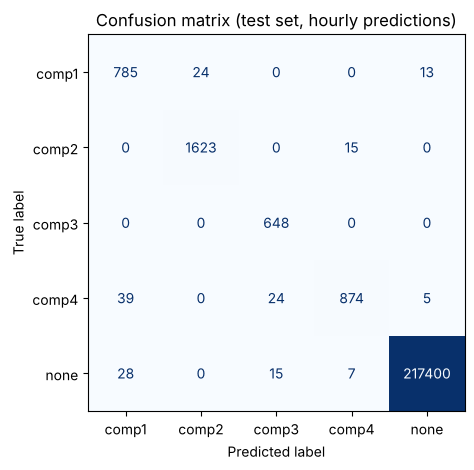

In [18]:
labels = COMPONENTS + ['none']
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=labels, cmap='Blues', colorbar=False)
plt.title('Confusion matrix (test set, hourly predictions)')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

Precision and recall are above 90 % for every component. Note that these metrics count **hours**, not failure events:
each failure produces 24 labelled hours.

The scores are high because the data is **simulated**: each component announces its failure through a clear,
dedicated warning and sensor pattern. Real device data would be noisier.
All features use only past information and the test period lies strictly after the training period, so the result is not caused by leakage.

## 9. Which features matter most?

Permutation importance: shuffle one feature at a time and measure how much the macro F1 score drops.
A balanced sample of the test set (all failure hours plus 10,000 `none` hours) keeps the runtime short.

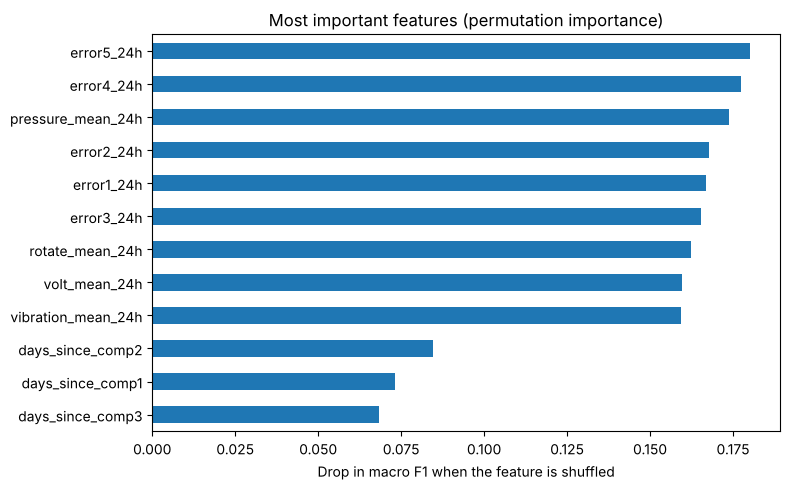

error5_24h            0.180
error4_24h            0.177
pressure_mean_24h     0.174
error2_24h            0.168
error1_24h            0.167
error3_24h            0.165
rotate_mean_24h       0.162
volt_mean_24h         0.160
vibration_mean_24h    0.159
days_since_comp2      0.085
days_since_comp1      0.073
days_since_comp3      0.068
days_since_comp4      0.063
model_model3          0.040
model_model4          0.003
model_model2          0.002
rotate_std_24h        0.000
volt_std_24h          0.000
pressure_std_24h     -0.000
model_model1         -0.000
age                  -0.001
vibration_std_24h    -0.002
dtype: float64

In [19]:
sample = pd.concat([test[test['label'] != 'none'],
                    test[test['label'] == 'none'].sample(10000, random_state=RANDOM_STATE)])

result = permutation_importance(model, sample[feature_cols], sample['label'],
                                scoring='f1_macro', n_repeats=3, random_state=RANDOM_STATE)
importance = pd.Series(result.importances_mean, index=feature_cols).sort_values()

importance.tail(12).plot(kind='barh', figsize=(8, 5), color='tab:blue')
plt.title('Most important features (permutation importance)')
plt.xlabel('Drop in macro F1 when the feature is shuffled')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

importance.sort_values(ascending=False).round(3)

- **Warnings and sensor levels** drive the predictions.
- **Days since the last replacement** help moderately.
- **Sensor variability, machine age and model** contribute almost nothing.

For short-term failure prediction, the **current state** of the machine matters far more than its static properties.

## Conclusion

- comp2 fails most often overall; comp3 is the main weak point of model1 and model2.
- Failures announce themselves one to two days in advance through a component-specific warning and sensor deviation.
- Combining warnings, sensor levels and maintenance history predicts which component will fail within 24 hours with over 90 % precision and recall per component on unseen months.

## Limitations and next steps

- The data is simulated, so real-world performance would be lower.
- Metrics are hourly; an event-level evaluation (how many failures were caught, and how early) would be closer to how a service team works.
- Only one model and one 24-hour window were tested. Longer windows, trend features or other models could be explored.
- Machines with several component failures at the same hour are labelled with only one of them.